In [1]:

import sys
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.control_effectiveness import (
    CONTROL_ASSUMPTIONS,
    evaluate_controls,
)

CONTROL_COST_SCENARIOS = {
    "C1_oauth_governance": {
        "low": 15000, "central": 30000, "high": 75000
    },
    "C2_least_privilege": {
        "low": 20000, "central": 35000, "high": 90000
    },
    "C3_saas_detection": {
        "low": 30000, "central": 60000, "high": 120000
    },
    "C4_data_protection": {
        "low": 25000, "central": 50000, "high": 110000
    },
    "C5_ir_readiness": {
        "low": 10000, "central": 25000, "high": 50000
    },
}

CONTROL_IDS = list(CONTROL_ASSUMPTIONS)

# Annual budgets to evaluate
BUDGETS = [0, 25000, 50000, 75000, 100000,
           150000, 200000, 300000, 450000]

N_INCIDENTS = 20000
SEED = 20261112

assert set(CONTROL_IDS) == set(CONTROL_COST_SCENARIOS)

print("Controls:", len(CONTROL_IDS))
print("Possible portfolios:", 2 ** len(CONTROL_IDS))


Controls: 5
Possible portfolios: 32


In [ ]:

# Enumerate all possible combinations, including no controls.

portfolios = [
    combo
    for r in range(len(CONTROL_IDS) + 1)
    for combo in combinations(CONTROL_IDS, r)
]

rows = []

for i, controls in enumerate(portfolios, start=1):
    print(f"Simulating portfolio {i}/{len(portfolios)}", end="\r")

    outcome = evaluate_controls(
        controls=list(controls),
        level="central",
        n_incidents=N_INCIDENTS,
        seed=SEED,
    )

    rows.append({
        "portfolio_id": i - 1,
        "controls": ", ".join(controls) if controls else "None",
        "control_count": len(controls),
        "control_ids": controls,
        "expected_lef": outcome["expected_lef"],
        "mean_incident_loss_usd": outcome["mean_incident_loss_usd"],
        "residual_aal_usd": outcome["aal_usd"],
    })

portfolio_risk = pd.DataFrame(rows)

baseline_aal = portfolio_risk.loc[
    portfolio_risk["control_count"] == 0,
    "residual_aal_usd"
].iloc[0]

portfolio_risk["risk_reduction_usd"] = (
    baseline_aal - portfolio_risk["residual_aal_usd"]
)

portfolio_risk["risk_reduction_pct"] = (
    100 * portfolio_risk["risk_reduction_usd"] / baseline_aal
)

assert len(portfolio_risk) == 32
assert portfolio_risk["residual_aal_usd"].gt(0).all()

print(f"\nBaseline AAL: ${baseline_aal:,.0f}")
print("Portfolios simulated:", len(portfolio_risk))

display(
    portfolio_risk[
        ["portfolio_id", "controls", "residual_aal_usd",
         "risk_reduction_usd", "risk_reduction_pct"]
    ].round(2)
)

#This runs 640,000 simulated successful incidents across 32 scenarios


Simulating portfolio 32/32
Baseline AAL: $272,950
Portfolios simulated: 32


,portfolio_id,controls,residual_aal_usd,risk_reduction_usd,risk_reduction_pct
0,0,None,272950.17,0.00,0.00
1,1,C1_oauth_governance,218360.14,54590.03,20.00
2,2,C2_least_privilege,239912.33,33037.84,12.10
3,3,C3_saas_detection,232007.65,40942.53,15.00
4,4,C4_data_protection,246203.78,26746.39,9.80
5,5,C5_ir_readiness,270401.39,2548.79,0.93
6,6,"C1_oauth_governance, C2_least_privilege",191929.87,81020.31,29.68
7,7,"C1_oauth_governance, C3_saas_detection",185606.12,87344.06,32.00
8,8,"C1_oauth_governance, C4_data_protection",196963.02,75987.15,27.84
9,9,"C1_oauth_governance, C5_ir_readiness",216321.11,56629.06,20.75


In [3]:
#Add costs and optimize across budgets
#Calculate each portfolio's annual incremental control spending, total expected annual cost, and net financial benefit.


financial_rows = []

for _, row in portfolio_risk.iterrows():
    controls = row["control_ids"]

    for cost_level in ["low", "central", "high"]:
        annual_cost = sum(
            CONTROL_COST_SCENARIOS[c][cost_level]
            for c in controls
        )

        residual_aal = row["residual_aal_usd"]

        financial_rows.append({
            "portfolio_id": row["portfolio_id"],
            "controls": row["controls"],
            "control_count": row["control_count"],
            "cost_level": cost_level,
            "annual_control_cost_usd": annual_cost,
            "residual_aal_usd": residual_aal,
            "risk_reduction_usd": row["risk_reduction_usd"],
            "total_expected_cost_usd": residual_aal + annual_cost,
            "net_annual_benefit_usd": (
                row["risk_reduction_usd"] - annual_cost
            ),
        })

portfolio_financial = pd.DataFrame(financial_rows)

optimization_rows = []

for cost_level in ["low", "central", "high"]:
    subset = portfolio_financial[
        portfolio_financial["cost_level"] == cost_level
    ]

    for budget in BUDGETS:
        feasible = subset[
            subset["annual_control_cost_usd"] <= budget
        ]

        # Objective A: lowest residual cyber risk
        min_risk = feasible.sort_values(
            ["residual_aal_usd", "annual_control_cost_usd",
             "portfolio_id"]
        ).iloc[0]

        # Objective B: lowest risk + investment cost
        min_total = feasible.sort_values(
            ["total_expected_cost_usd", "annual_control_cost_usd",
             "portfolio_id"]
        ).iloc[0]

        for objective, selected in [
            ("Minimize residual risk", min_risk),
            ("Minimize total expected cost", min_total),
        ]:
            optimization_rows.append({
                "cost_level": cost_level,
                "budget_usd": budget,
                "objective": objective,
                "portfolio_id": selected["portfolio_id"],
                "controls": selected["controls"],
                "annual_control_cost_usd": (
                    selected["annual_control_cost_usd"]
                ),
                "residual_aal_usd": selected["residual_aal_usd"],
                "total_expected_cost_usd": (
                    selected["total_expected_cost_usd"]
                ),
                "net_annual_benefit_usd": (
                    selected["net_annual_benefit_usd"]
                ),
            })

optimization_results = pd.DataFrame(optimization_rows)

# Main decision table: central costs, both objectives
central_optimal = optimization_results[
    optimization_results["cost_level"] == "central"
].copy()

display(
    central_optimal[
        ["budget_usd", "objective", "controls",
         "annual_control_cost_usd", "residual_aal_usd",
         "total_expected_cost_usd", "net_annual_benefit_usd"]
    ].style.format({
        "budget_usd": "${:,.0f}",
        "annual_control_cost_usd": "${:,.0f}",
        "residual_aal_usd": "${:,.0f}",
        "total_expected_cost_usd": "${:,.0f}",
        "net_annual_benefit_usd": "${:,.0f}",
    })
)


,budget_usd,objective,controls,annual_control_cost_usd,residual_aal_usd,total_expected_cost_usd,net_annual_benefit_usd
18,$0,Minimize residual risk,None,$0,"$272,950","$272,950",$0
19,$0,Minimize total expected cost,None,$0,"$272,950","$272,950",$0
20,"$25,000",Minimize residual risk,C5_ir_readiness,"$25,000","$270,401","$295,401","$-22,451"
21,"$25,000",Minimize total expected cost,None,$0,"$272,950","$272,950",$0
22,"$50,000",Minimize residual risk,C1_oauth_governance,"$30,000","$218,360","$248,360","$24,590"
23,"$50,000",Minimize total expected cost,C1_oauth_governance,"$30,000","$218,360","$248,360","$24,590"
24,"$75,000",Minimize residual risk,"C1_oauth_governance, C2_least_privilege","$65,000","$191,930","$256,930","$16,020"
25,"$75,000",Minimize total expected cost,C1_oauth_governance,"$30,000","$218,360","$248,360","$24,590"
26,"$100,000",Minimize residual risk,"C1_oauth_governance, C3_saas_detection","$90,000","$185,606","$275,606","$-2,656"
27,"$100,000",Minimize total expected cost,C1_oauth_governance,"$30,000","$218,360","$248,360","$24,590"


The financially optimal portfolio may remain unchanged as the budget increases. That is a valid result: spending more does not necessarily create more financial value.

The minimum-risk portfolio, by contrast, will generally use more controls as the budget increases.

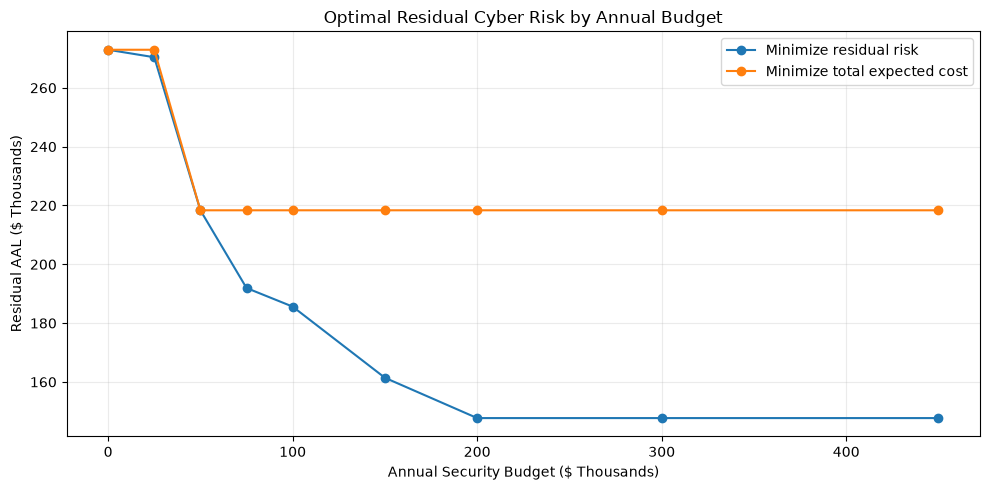

STEP 9 RESULTS GENERATED
Baseline AAL: $272,950
Portfolios evaluated: 32
Cost scenarios: low, central, high
Optimization objectives: 2
All validation checks passed.
Saved three CSV files to outputs/


In [4]:

#Visualization, validation, and export
fig, ax = plt.subplots(figsize=(10, 5))

for objective in [
    "Minimize residual risk",
    "Minimize total expected cost",
]:
    subset = central_optimal[
        central_optimal["objective"] == objective
    ].sort_values("budget_usd")

    ax.plot(
        subset["budget_usd"] / 1000,
        subset["residual_aal_usd"] / 1000,
        marker="o",
        label=objective,
    )

ax.set_title("Optimal Residual Cyber Risk by Annual Budget")
ax.set_xlabel("Annual Security Budget ($ Thousands)")
ax.set_ylabel("Residual AAL ($ Thousands)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Validation
assert len(portfolio_financial) == 32 * 3
assert len(optimization_results) == len(BUDGETS) * 3 * 2

assert (
    optimization_results["annual_control_cost_usd"]
    <= optimization_results["budget_usd"]
).all()

# No-control baseline should be the same across cost scenarios.
assert portfolio_financial.loc[
    portfolio_financial["control_count"] == 0,
    "annual_control_cost_usd"
].eq(0).all()

# Financially optimal total cost cannot exceed the
# no-control baseline (which is always feasible).
financial_optima = optimization_results[
    optimization_results["objective"]
    == "Minimize total expected cost"
]

assert (
    financial_optima["total_expected_cost_usd"]
    <= baseline_aal + 1e-6
).all()

# Increasing budget cannot worsen the optimal objective.
for (level, objective), group in optimization_results.groupby(
    ["cost_level", "objective"]
):
    metric = (
        "residual_aal_usd"
        if objective == "Minimize residual risk"
        else "total_expected_cost_usd"
    )
    values = group.sort_values("budget_usd")[metric].to_numpy()
    assert (np.diff(values) <= 1e-6).all()

output_dir = PROJECT_ROOT / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# Remove tuple-valued column from CSV output.
portfolio_risk.drop(columns=["control_ids"]).to_csv(
    output_dir / "09_portfolio_risk.csv",
    index=False,
)

portfolio_financial.to_csv(
    output_dir / "09_portfolio_financial.csv",
    index=False,
)

optimization_results.to_csv(
    output_dir / "09_optimization_results.csv",
    index=False,
)

print("STEP 9 RESULTS GENERATED")
print(f"Baseline AAL: ${baseline_aal:,.0f}")
print("Portfolios evaluated: 32")
print("Cost scenarios: low, central, high")
print("Optimization objectives: 2")
print("All validation checks passed.")
print("Saved three CSV files to outputs/")



## Step 9 — Final Results and Investment Recommendation

### Objective

Identify the optimal combination of five cybersecurity controls for
NovaFlow under different annual investment budgets.

We evaluated all 32 possible control portfolios using two objectives:

1. **Risk minimization:** Minimize residual Annual Average Loss (AAL).
2. **Financial optimization:** Minimize residual AAL plus annual control costs.

We considered low, central, and high implementation cost assumptions
and nine annual security budgets.

### Key Findings

**1. Baseline cyber risk**

NovaFlow's estimated baseline AAL is approximately **$272,950**,
for the modeled third-party OAuth-token compromise scenario.

**2. Financially optimal portfolio — Central assumptions**

The optimal investment is **C1: Third-party OAuth Governance**.

- Annual investment: **$30,000**
- Expected residual AAL: **$218,360**
- Expected annual risk reduction: **$54,590 (20%)**
- Net annual financial benefit: **+$24,590**
- Net ROI: **approximately 82%**

C1 remains financially optimal for all tested budgets of $50,000
or greater under central cost and effectiveness assumptions.

Adding other controls reduces residual risk further, but the
additional expected loss reduction does not justify their
incremental costs in this single-scenario model.

**3. Maximum risk reduction**

Implementing all five controls reduces AAL to approximately
**$147,706**, representing a **45.9% reduction**.

However, under central costs:

- Total annual investment: **$200,000**
- Gross annual risk reduction: **$125,245**
- Net annual financial benefit: **−$74,755**

Therefore, maximum risk reduction does not necessarily maximize
financial value.

**4. Sensitivity to control costs**

The financially optimal investment changes with cost assumptions:

| Cost scenario | Optimal portfolio | Net annual benefit |
|---|---|---:|
| Low | C1 + C2 | +$46,020 |
| Central | C1 | +$24,590 |
| High | No controls | $0 |

These recommendations assume the investment budget is sufficient
to implement the selected portfolio.

### Final Recommendation

Under the central assumptions, NovaFlow should prioritize
**third-party OAuth application governance (C1)** as its first
investment to reduce the modeled vendor-credential compromise risk.

If implementation costs are lower than expected, combining
**OAuth governance (C1)** with **least-privilege integration access
(C2)** becomes the financially preferred alternative.

Other controls may still be justified by their benefits against
additional cyberattack scenarios, compliance requirements,
organizational risk appetite, or tail-risk reduction objectives.

### Limitations

- The analysis covers one confidentiality-related cyberattack
  scenario, not NovaFlow's entire cybersecurity risk portfolio.
- Control effectiveness and costs are illustrative assumptions,
  not empirically validated estimates.
- Controls are modeled as binary investments (implemented/not
  implemented), rather than continuous spending decisions.
- The optimization focuses on AAL, not VaR or TVaR.
- Monte Carlo sampling uncertainty may affect close rankings.
- Benefits against other cyber risks are excluded.

### Conclusion

The analysis demonstrates how FAIR-based cyber risk quantification
can support financially informed cybersecurity investment decisions.

Rather than automatically selecting the maximum number of security
controls, NovaFlow can compare their incremental expected risk
reduction against implementation costs and budget constraints.

**Step 9 status: Complete for exploratory investment optimization.**
